# Fatoumata NDOUR 22321513 

# Devoir Maison: Optimisation Pour Le Machine Learning

## Objectif:
Rendre un notebook jupyter bien commenté, propre et reproductible en utilisant **Pytorch**.

Afin de montrer que certains concepts vus en cours ont été compris, un code avec des expériences et 

des figures dont les choix seront justifiés sont attendus.
  
Ce rendu comporte deux partie: **Speed restart (Nesterov)** et **Scaling law pour le stepsize (méthode du gradient)**.

## Importation des librairies requises

In [2]:
# A installer si pas déjà fait
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

## Definition de la fonction RosenBrock en dimension 2

$$
f(x, y) = (1 - x)^2 + 100 (y - x^2)^2
$$


In [3]:
# Implémentation

def rosenbrock(x):
    """
    Fonction de Rosenbrock 2D :
    F(x, y) = (1 - x)^2 + 100 * (y - x^2)^2
    """
    y = 1-x[0]
    z = y**2
    w = x[0]**2
    u = x[1] - w
    v = u**2
    t = 100 * v
    return z + t

## Partie I : Speed restart (Nesterov)

Dans cette partie, on dois implémenter et comparer deux variantes de la méthode de Nesterov Accelerated 

Gradient (NAG) sur la fonction de Rosenbrock (en 2 dimensions), en utilisant b=3 et en déduire lequel 

des deux est le meilleur.

### I.1 Implémentation du Nesterov Accelerated Gradient avec Speed Restart  
Le principe est de réinitialiser le momentum à zéro chaque fois que la "vitesse" décrite par la 

norme de la différence successive des positions diminue, ce qui signifie une perte d'élan dans 

la progression vers le minimum.

$$
\begin{cases}
x_{k+1} = y_k - \alpha \, \nabla F(y_k) \\
y_{k+1} = x_{k+1} + \beta_j \, (x_{k+1} - x_k)
\end{cases}
\quad \text{avec} \quad \beta_j = \frac{j}{j + b}, \quad b=3
$$

Condition de redémarrage ("Speed Restart") :
$$
\|x_{k+1} - x_k\| < \|x_k - x_{k-1}\| \Rightarrow j = 0
$$


In [4]:
def nesterov_speed_restart(x_0, fonction, alpha=0.001, b=3, k_min=10, n_steps=2000, tol=1e-8):
    """
    Implémente Nesterov Accelerated Gradient (NAG) avec Speed Restart.

    Args:
        x_0: tensor initial (dimension d) 
        fonction: fonction qui calcule le gradient de F
        alpha: pas d'apprentissage
        b: paramètre d'inertie (ici b=3)
        k_min: nombre minimal d'itérations avant restart
        n_steps: nombre total d'itérations
        tol: tolérance pour critère d’arrêt

    Returns:
        liste des valeurs de F et des points x_k
    """
    # Initialisation
    x_prev = x_0.clone()
    x = x_0.clone()
    y = x.clone().requires_grad_(True)
    j = 0  # compteur d'inertie
    values = []
    trajectory = [x.clone()]

    for k in range(n_steps):
        # Calcul du gradient
        loss = fonction(y)
        loss.backward()
        
        with torch.no_grad():
            x_next = y - alpha * y.grad
            beta = j / (j + b)
            y_next = x_next + beta * (x_next - x)

            # Condition de redémarrage (Speed Restart)
            if torch.norm(x_next - x) < torch.norm(x - x_prev) and j >= k_min:
                j = 0
            else:
                j += 1

            x_prev.copy_(x)
            x.copy_(x_next)
            y.copy_(y_next)

            # Enregistrement
        values.append(fonction(x).item())
        trajectory.append(x.clone())

        # Nettoyer le gradient pour éviter accumulation
        y.grad.zero_()
        

        # Critère d'arrêt
        if torch.norm(x - x_prev) < tol:
            break

    return values, trajectory


### I.2 Implémentation du Nesterov Accelerated Gradient (NAG) avec vanishing friction.


C’est la version sans restart, où le coefficient d’inertie  diminue progressivement avec k.
#### Rappel de la formule (vue dans le cours)

La méthode s’écrit :
$$
\begin{cases}
x_{k+1} = y_k - \alpha \nabla F(y_k) \\
y_{k+1} = x_{k+1} + \beta_k (x_{k+1} - x_k)
\end{cases}
$$
avec :
$$
\beta_k = \frac{k}{k + b}
$$

et ici on prend \( b = 3 \).

In [5]:
def nesterov_vanishing_friction(x_0, fonction, alpha=0.001, b=3, n_steps=2000, tol=1e-8):
    """
    Implémente Nesterov Accelerated Gradient (NAG) avec friction décroissante (vanishing friction).
    """

    x = x_0.clone()
    y = x.clone().requires_grad_(True)
    values = []
    trajectory = [x.clone()]

    for k in range(1, n_steps + 1):
        # Nettoyage du gradient avant backward
        if y.grad is not None:
            y.grad.zero_()
        
        # Calcul du gradient en y (point d'anticipation)
        loss_y = fonction(y)
        loss_y.backward()

        with torch.no_grad():
            # Sauvegarde de x pour le critère d'arrêt
            x_old = x.clone()

            # Mise à jour Nesterov
            x_next = y - alpha * y.grad
            beta = k / (k + b)
            y_next = x_next + beta * (x_next - x)

            # Avancer dans la boucle
            x.copy_(x_next)
            y.copy_(y_next)


        # Enregistrement
        values.append(fonction(x).item())
        trajectory.append(x.clone())

        # Critère d'arrêt
        if torch.norm(x - x_old) == 0:
            break

    return values, trajectory


### I.3 Application des deux algorithmes sur le Rosenbrock

In [6]:
# Initialisation
x0 = torch.tensor([1., 0.5], dtype=torch.float32)

# Exécution
values1, traj1 = nesterov_speed_restart(
    x0,
    rosenbrock,
    alpha=0.001,
    b=3,
    k_min=10,
    n_steps=2000
)
values2, traj2 = nesterov_vanishing_friction(
     x0,
    rosenbrock,
    alpha=0.001,
    b=3,
    n_steps=2000
)
# Histoire de voir les dernières sorties
print("Dernière valeur de F_speed :", values1[-1])
print("Dernier point trouvé :", traj1[-1])
print("Dernière valeur de F_vanishing :", values2[-1])
print("Dernier point trouvé :", traj2[-1])


Dernière valeur de F_speed : 1.4794387936944986e-09
Dernier point trouvé : tensor([1.0000, 0.9999])
Dernière valeur de F_vanishing : 8.043972457016935e-07
Dernier point trouvé : tensor([1.0009, 1.0018])


### I.4 Visualisation des résultats

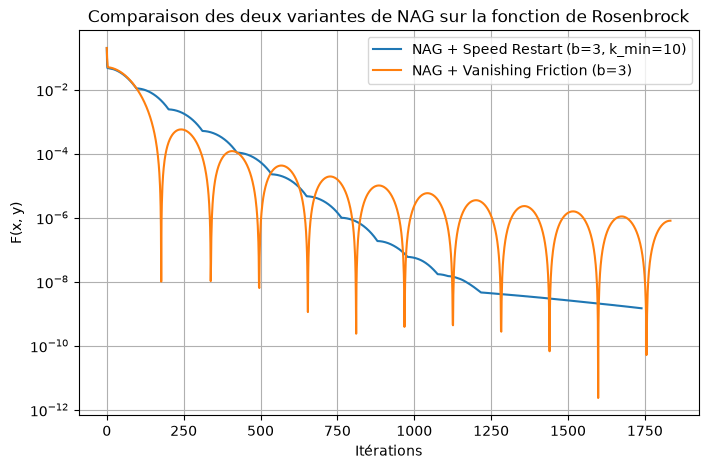

In [7]:
plt.figure(figsize=(8,5))
plt.semilogy(values1, label="NAG + Speed Restart (b=3, k_min=10)")
plt.semilogy(values2, label="NAG + Vanishing Friction (b=3)")
plt.title("Comparaison des deux variantes de NAG sur la fonction de Rosenbrock")
plt.xlabel("Itérations")
plt.ylabel("F(x, y)")
plt.grid(True)
plt.legend()
plt.show()

### I.5 Explications

#### Choix des hyperparamètres

Nous optimisons la fonction de Rosenbrock sur l’intervalle:$$ x \in [-2,2], y \in [-1,3], $$
où elle est lisse et localement convexe autour du minimum global (1,1).

Le point initial x_0=(1,0.5) est choisi d’après le graphe des test functions vu en cours :il se situe dans 

la zone convexe de la vallée, tandis que les points en dehors de cet intervalle entraînent souvent une 

divergence ou une précision moindre.

Le pas d’apprentissage est fixé à $$alpha = 0.001 \approx 1/L,  avec L \simeq 10^3$$  la constante de Lipschitz locale car elle garantit que l’algorithme ne divergera pas dans la zone convexe choisie  .

Le nombre maximal d’itérations est $$ K_{\max}=2000 $$ afin de limiter le temps de calcul.

L’algorithme peut s’arrêter plus tôt si la différence entre deux itérations consécutives devient très petite $$ |x_{k+1} - x_k| < 10^{-8}.$$

Pour la version Speed Restart, un  $$k_{\min}=10$$  est utilisé afin d’éviter des redémarrages trop précoces et 

permettre une comparaison significative avec la version Vanishing Friction.

Ces réglages garantissent une comparaison équilibrée et stable entre les deux variantes du Nesterov accéléré.
$$

#### Comparaison:

Avec les choix d’hyperparamètres et le nombre d’itérations retenus, le graphe montre que

la variante Vanishing Friction accélère fortement la convergence initiale mais présente

d’importantes oscillations, traduisant une certaine instabilité dynamique.

À l’inverse, la variante Speed Restart converge plus lentement mais de manière monotone et stable,

atteignant une valeur finale plus régulière.

Ainsi, le Speed Restart apparaît comme le meilleur choix global, même en testant des pas

d’apprentissage et des nombres d’itérations différents par exemple en conservant les mêmes 

réglages (meilleurs) pour Speed Restart et en prenant alpha_vanishing=0.0005 avec N_vanishing=1540.

Cette méthode offre une convergence monotone, robuste et une meilleure précision finale, 

ce qui en fait la méthode la plus fiable sur la fonction de Rosenbrock dans le cadre de notre expérience.

## Partie II : Scaling law pour le stepsize (méthode du gradient)

Le but de cette partie est de fournir des recommandations pour choisir le pas (stepsize) quand 

on entraîne un modèle, à mesure que la taille du modèle augmente.


### I.1 Entraînement du modéle avec d = 16 utilisant la méthode du gradient

#### Rappel

Les données sont générées en utilisant la formule suivante:

$$
y_i = \sin(t_i) + \varepsilon_i, \quad t_i \in [-T, T], \quad \varepsilon_i \sim \mathcal{N}(0, \sigma^2),
n = 200, T = 5, σ = 0.1.
$$

Le modèle à entraîner ici est un petit réseau de neurones Avec ReLU comme fonction d'activation:
$$
h(\mathbf{w}_1, \mathbf{w}_2, \mathbf{b}_1, \mathbf{b}_2, t) = \mathbf{w}_2 \cdot \text{ReLU}(\mathbf{w}_1 t + \mathbf{b}_1) + \mathbf{b}_2,
$$
où 
$$
\mathbf{w}_1, \mathbf{b}_1, \mathbf{w}_2 \in \mathbb{R}^d, \mathbf{b}_2 \in \mathbb{R}
$$

et la fonction ReLU est appliquée composante par composante :

$$
\text{ReLU}(z) = \max(0, z).
$$

Le problème d’apprentissage sur l’ensemble des données $$\{(t_i, y_i)\}_{i=1}^n$$ s’écrit alors :

$$
\min_{x \in \mathbb{R}^p} \frac{1}{n} \sum_{i=1}^n \left( h(x, t_i) - y_i \right)^2.
$$



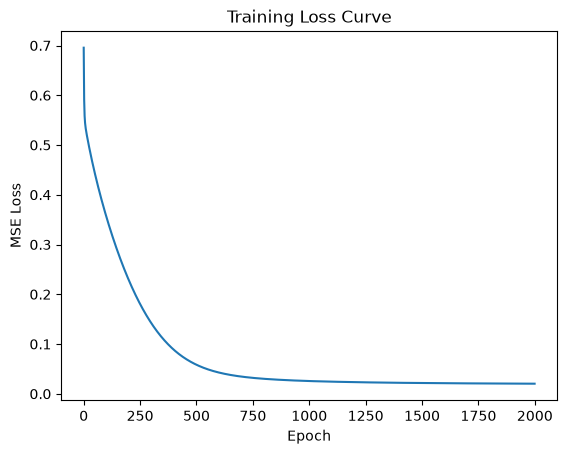

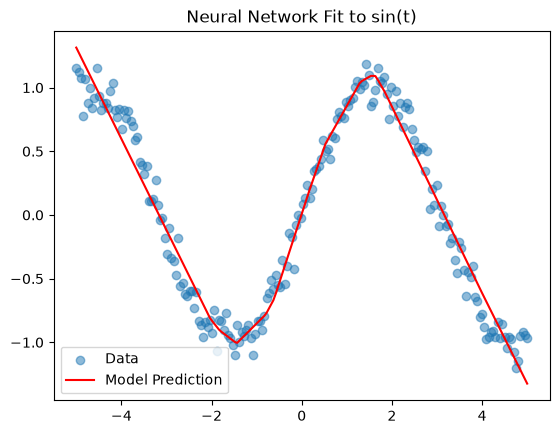

In [8]:
# ----------------------
# Data generation
# ----------------------
def generate_data(n=200, T=5, sigma=0.1, seed=42):
    torch.manual_seed(seed)
    t = torch.linspace(-T, T, n).unsqueeze(1)  # shape (n,1)
    y = torch.sin(t) + sigma * torch.randn_like(t)
    return t, y

# ----------------------
# Model definition
# ----------------------
class SimpleNN(nn.Module):
    def __init__(self, d=16):
        super(SimpleNN, self).__init__()
        self.hidden = nn.Linear(1, d)   # input: t (1D) → hidden (dD)
        self.relu = nn.ReLU()
        self.output = nn.Linear(d, 1)   # hidden (dD) → output (1D)
        
    def forward(self, t):
        return self.output(self.relu(self.hidden(t)))

# ----------------------
# Training loop
# ----------------------
def train_model(d=16, lr=1e-2, n_epochs=2000):
    # Data
    t, y = generate_data()
    
    # Model
    model = SimpleNN(d=d)
    criterion = nn.MSELoss()
    optimizer = optim.SGD(model.parameters(), lr=lr)
    
    losses = []
    for epoch in range(n_epochs):
        optimizer.zero_grad()
        y_pred = model(t)
        loss = criterion(y_pred, y)
        loss.backward()
        optimizer.step()
        
        losses.append(loss.item())
    
    return model, t, y, losses

# ----------------------
# Run experiment
# ----------------------
if __name__ == "__main__":
    model, t, y, losses = train_model(d=16, lr=0.01)
    
    # Plot training loss
    plt.plot(losses)
    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")
    plt.title("Training Loss Curve")
    plt.show()
    
    # Plot predictions vs true values
    with torch.no_grad():
        y_pred = model(t)
    plt.scatter(t.numpy(), y.numpy(), label="Data", alpha=0.5)
    plt.plot(t.numpy(), y_pred.numpy(), color="red", label="Model Prediction")
    plt.legend()
    plt.title("Neural Network Fit to sin(t)")
    plt.show()

On va maintenant trouver le meilleur pas d’apprentissage sachant que d=16 et que la méthode de la descente du 

gradient en full batch est utilisée. On définit une grille de valeurs pour α et on entraîne le modèle avec ces 

différentes valeurs pour déterminer celle qui optimise le mieux la convergence.

In [9]:
# cette fonction définie pour un d donné les différentes valeurs de la MSE sur une grille de alpha
alphas = np.logspace(-4, -1, 13)        # grille de pas d'apprentissage

def meilleur_alpha(d):
    lossfinal = []
    for alpha in alphas:
        res = train_model(d, alpha)
        lossfinal.append(res[-1][-1]) # on récupere la dernière valeur de la liste des perte
     # On identifie l'indice du minimum
    idx_best = np.nanargmin(lossfinal)
    best_alpha = alphas[idx_best]
    best_loss = lossfinal[idx_best]
    return lossfinal,best_alpha,best_loss


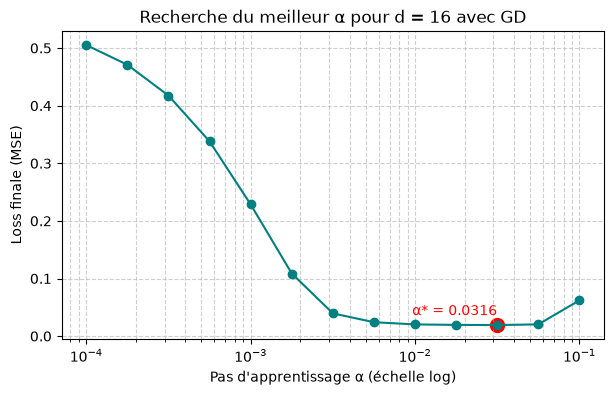


Meilleur pas α* = 0.03162  avec une loss finale = 0.01922


In [10]:
res = meilleur_alpha(16)
plt.figure(figsize=(7,4))
plt.semilogx(alphas, res[0], marker='o', color='teal')
# Ajouter le point optimal en rouge
plt.scatter(res[1], res[2], color='red', s=100, label=f"α* = {res[1]:.3g}")
# Annoter la position du point
plt.text(res[1], res[2]*1.9, f"α* = {res[1]:.3g}", color='red', ha='right')

plt.xlabel("Pas d'apprentissage α (échelle log)")
plt.ylabel("Loss finale (MSE)")
plt.title("Recherche du meilleur α pour d = 16 avec GD")
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.show()

print(f"\nMeilleur pas α* = {res[1]:.4g}  avec une loss finale = {res[2]:.5f}") 

### II.2 Scaling law pour le pas de l'apprentissage aprés avoir varié d plusieurs fois

Dans cette partie, on définit une grille de valeurs pour d et on utilise la fonction **meilleur_alpha**

pour trouver le meilleur alpha sachant que ce dernier est prise dans une plage de valeurs.

In [ ]:
# Grille de d 
liste_d = [5,20,30,50,80]

# Dictionnaire pour stocker les résultats
resultats_d = {}

# Calcul pour chaque d
for d in liste_d:
    losses_finales, best_alpha, best_loss = meilleur_alpha(d)
    resultats_d[d] = (losses_finales, best_alpha, best_loss)
    print(f"d={d:>2} | α*={best_alpha:.4g} | loss={best_loss:.5f}")

d= 5 | α*=0.05623 | loss=0.02181


In [ ]:
plt.figure(figsize=(8,5))
colors = plt.cm.tab10(np.linspace(0, 1, len(liste_d)))

offset = 0.01  # décalage vertical entre chaque courbe

for i, d in enumerate(liste_d):
    losses, best_alpha, best_loss = resultats_d[d]
    plt.semilogx(alphas, np.array(losses) + i*offset, color=colors[i], lw=1, label=f"d={d}")
    plt.scatter(best_alpha, best_loss + i*offset, color='red', s=25, zorder=5)

plt.title("Descente de gradient : influence de d sur le pas d’apprentissage", fontsize=13)
plt.xlabel("Pas d’apprentissage α (échelle log)", fontsize=11)
plt.ylabel("Loss finale (MSE) + offset (pour lisibilité)", fontsize=11)
plt.grid(True, which="both", ls="-", alpha=0.6)
plt.legend(title="Taille de la couche cachée d", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()


#### Fonction du scaling law avec d comme variable

$$
\alpha^*(d) \approx \nu \, d^{\gamma}
$$
où $$\alpha^*(d)$$ est le pas optimal mesuré pour une taille cachée d.
On estime $$\nu > 0  et  \gamma \in \mathbb{R} $$ par régression linéaire en log–log selon la relation :
$$
\log \alpha^*(d) = \log \nu + \gamma \log d.
$$

In [ ]:
# Récupère les alpha* mesurés
ds = np.array(sorted(resultats_d.keys()), dtype=float)
alpha_stars = np.array([resultats_d[int(d)][1] for d in ds], dtype=float)

# Fit log–log : log(alpha*) = a + gamma*log(d)  =>  nu = exp(a)
logd, loga = np.log(ds), np.log(alpha_stars)
gamma, a = np.polyfit(logd, loga, 1)
nu = float(np.exp(a))
print(f"Loi d’échelle estimée :  alpha*(d) ≈ {nu:.3e} * d^{gamma:.3f}")

# Graphique log–log
plt.figure(figsize=(6.2,4.6))
plt.loglog(ds, alpha_stars, 'o', label="α* mesurés")
dgrid = np.linspace(ds.min(), ds.max(), 200)
plt.loglog(dgrid, nu*(dgrid**gamma), '-', label=f"Fit: ν={nu:.2e}, γ={gamma:.3f}")
plt.xlabel("Taille de la couche cachée d (log)")
plt.ylabel("Pas optimal α* (log)")
plt.title("Loi d’échelle du pas optimal")
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


### II.3 Analyse et interprétation des résultats

Nous avons mesuré le pas d’apprentissage optimal α(d) pour plusieurs tailles de couche cachée 

d ∈ {5,20,30,50,80}. Les valeurs optimales α(d) ont ensuite été ajustées selon une loi d’échelle du type :

$$\alpha(d) \approx \nu d^{\gamma}.$$ La régression log–log donne : $$\nu \approx 1.47 \times 10^{-1}, \quad \gamma \approx -0.472.$$

Les expériences montrent une **décroissance du pas d’apprentissage optimal α(d)**  lorsque 

la taille d de la couche cachée augmente. Autrement dit, **plus le réseau est large**, 

plus le pas d’apprentissage doit être **petit** pour garantir la stabilité de la descente de gradient.

Cette tendance est **parfaitement cohérente** avec l’intuition théorique :  

un modèle plus large possède davantage de paramètres, donc des **gradients plus grands ou plus variables**,  

ce qui exige un **pas d’apprentissage réduit** afin d’éviter les oscillations ou la divergence de la descente.

#### Choix de la grille de pas α

Le choix de la **grille de valeurs de α** utilisée pour les tests n’a pas été arbitraire.  

Il s’est appuyé sur un **pas de référence** issu du premier test (pour d = 16 ), autour duquel 

a été construite une **grille logarithmique** adaptée.  

L’objectif de cette construction était double :

1. **Assurer la convergence** du gradient descent pour toutes les tailles d éviter les pas trop 

grands qui provoquent une divergence de la loss.

2. **Rendre la comparaison entre modèles significative** en gardant la même échelle d’α autour du 

pas typique, pour observer des différences liées uniquement à la taille du modèle.

Ainsi, la **longueur et la densité de la grille** ont été calibrées pour capturer à la fois :

- la **zone de stabilité** (α petits, descente lente mais sûre),

- et le **voisinage du minimum** (α trop grands : début de divergence).

Cette approche garantit que les valeurs de α(d) estimées traduisent un compromis cohérent 

entre **vitesse de convergence** et **stabilité numérique**, permettant une comparaison 

fiable entre les différentes tailles de réseau.